# **SAMson: An Automated Brain Extraction Tool for Rodents Using SAM**  
*Accurate and robust rodent brain segmentation for MRI data*

---

### **Authored by**  
**Daniel Panadero Soler**<sup>1</sup>, **Mohamed Kotb Selim**<sup>1</sup>, **Patricia Martínez-Tazo**<sup>1</sup>,  
**Emma Muñoz-Moreno**<sup>2</sup>, **Pedro Ramos-Cabrer**<sup>3,4</sup>, **Pilar López-Larrubia**<sup>5</sup>,  
**Silvia De Santis**<sup>1</sup>, **Santiago Canals**<sup>1</sup>, and **Antonio Pertusa**<sup>6</sup>  

<sup>1</sup>Instituto de Neurociencias, CSIC-UMH, Sant Joan d’Alacant, Spain  
<sup>2</sup>IDIBAPS, Barcelona, Spain  
<sup>3</sup>CIC biomaGUNE, BRTA, Donostia–San Sebastián, Spain  
<sup>4</sup>Ikerbasque, Basque Foundation for Science, Bilbao, Spain  
<sup>5</sup>Instituto de Investigaciones Biomédicas Sols-Morreale, CSIC-UAM, Madrid, Spain  
<sup>6</sup>University Institute for Computer Research, University of Alicante, Alicante, Spain  

📧 **Contact**: [pertusa@ua.es](mailto:pertusa@ua.es)  

---

### **Abstract**
**Background and objective.** Accurate brain extraction is a critical step in the analysis of rodent head magnetic resonance imaging (MRI) data. However, current methods often encounter difficulties in handling the diverse range of imaging setups, resolutions, and experimental conditions that are commonly found in this field.  
**Methods.** Based on the Segment Anything Model (SAM), we introduce here SAMson (*SAM for Segmentation Of Neuroimages*), an automated tool for robust rodent brain extraction. SAMson integrates a bounding box generator and a mask prediction pipeline, offering fully automated and semi-automated modes to address varying experimental complexities.  
**Results.** The performance of SAMson was evaluated using seven multi-center rodent MRI [datasets](https://doi.org/10.20350/digitalCSIC/17000) annotated at the pixel level, which differed in terms of acquisition parameters, contrast (T2-weighted, T2\*-weighted and diffusion-weighted images), resolution, anteroposterior coverage and animal age groups. SAMson outperformed the nine methods tested, BET, BET4Animal, RBM, BEN, SHERM, ANTs, deepbet, MedSAM and SAM2, in segmentation accuracy (significantly in 87 of 90 dataset–method comparisons), with mean Jaccard indices of 89.0–94.7%. The semi-automated mode demonstrates particular efficacy in challenging scenarios, including low-resolution images and cases requiring refined mask precision.  
**Conclusions.** In contrast to conventional volumetric techniques, SAMson's errors are confined to a few individual slices, thereby enabling rapid and targeted correction when needed. By providing open-source access, SAMson aims to support large-scale research workflows and advance translational neuroscience. The curated data can be downloaded from https://doi.org/10.20350/digitalCSIC/17000, and the code is available at https://github.com/CanalsLab/SAMson, as an installable Python package (samson-mri) with a command-line interface, a Python API and a graphical application.

---

### **Contents**
This notebook evaluates the nine other methods. SAMson itself is evaluated in `SAMson_experiments.ipynb`, and `SAMson_figures_and_statistics.ipynb` produces the figures and statistics. For every comparator tool it gives the version, environment and command, generates the masks of the 409 scans of the 10 dataset-contrasts (D1–D7, `datasets/`) with the library of the full run (`notebooks/lib`) and evaluates them:
1. SAMson's boxes with the [SAM2 model](https://github.com/facebookresearch/sam2).
2. SAMson's boxes with the fine-tuned [MedSAM model](https://github.com/bowang-lab/MedSAM) (Jun Ma, Sumin Kim, Feifei Li, Mohammed Baharoon, Reza Asakereh, Hongwei Lyu, Bo Wang. Segment Anything in Medical Images and Videos: Benchmark and Deployment).
3. [BET](https://fsl.fmrib.ox.ac.uk/fsl/docs/#/structural/bet) (Smith SM. Fast robust automated brain extraction. Hum Brain Mapp. 2002 Nov;17(3):143-55. doi: 10.1002/hbm.10062).
4. [BET4Animal](https://fsl.fmrib.ox.ac.uk/fsl/docs/structural/bet.html) (script distributed with FSL ≥ 6.0.6.6; BET after species-specific voxel rescaling).
5. [deepbet](https://github.com/wwu-mmll/deepbet) (Fisch L, et al. "deepbet: Fast brain extraction of T1-weighted MRI using Convolutional Neural Networks". Computers in Biology and Medicine 2024; 179:108845).
6. [BEN](https://github.com/yu02019/BEN) (Yu Z, et al. A generalizable brain extraction net (BEN) for multimodal MRI data from rodents, nonhuman primates, and humans. Elife. 2022;11:e81217. doi: 10.7554/eLife.81217).
7. [Rodent U-net (RBM)](https://github.com/CAMRIatUNC/RodentMRISkullStripping) (Hsu LM, et al. Automatic Skull Stripping of Rat and Mouse Brain MRI Data Using U-Net. Front Neurosci. 2020;14:568614. DOI: 10.3389/fnins.2020.568614).
8. [ANTs](https://github.com/ANTsX/ANTs) (Tustison N, et al. "The ANTsX ecosystem for quantitative biological and medical imaging". Scientific Reports 2021; 11(1):9068).
9. [SHERM](https://github.com/liu-yikang/SHERM-rodentSkullStrip) (Liu Y, Unsal HS, Tao Y, Zhang N. Automatic Brain Extraction for Rodent MRI Images. Neuroinformatics. 2020;18(3):395-406. doi: 10.1007/s12021-020-09453-z), run in MATLAB on two other computers: its masks (`outputs/masks/sherm/`) are only evaluated here, and its run times are taken from its logs (`outputs/sherm/`).

All scans are evaluated, on every slice with brain in the reference mask, in every dataset. The metrics of every slice and scan are saved to `results/exp_tools_slices.csv` and `results/exp_tools_subjects.csv`, and the SHERM run times of the masks used to `results/sherm_runtimes.csv` (read by `SAMson_figures_and_statistics`). After the evaluation of each tool, `plot_median_scans` shows the central evaluated slice of its median scan (per-scan Jaccard closest to the median) in each dataset-contrast, with the layout of Fig. 5 (D1: 3-month mice). With `PLOTS = True`, the slices of the scan with median performance (mean slice Jaccard) of each dataset-contrast are plotted (not done by default, to limit the file size).

## Setup

In [ ]:
import os                                                                       # files
import sys                                                                      # library path
import cv2                                                                      # images  # type: ignore
import matplotlib.pyplot as plt                                                 # plots
import numpy as np                                                              # arrays
import pandas as pd                                                             # tables
import nibabel as nib                                                           # nifti  # type: ignore
from os.path import join as pjoin                                               # join paths
from matplotlib.font_manager import FontProperties                              # plot titles
from scipy import ndimage                                                       # image processing
%config InlineBackend.figure_formats = ["jpeg"]                                 # JPEG figures: a notebook about 7 times smaller

"""""  INPUTS  (ADAPT  FOLLOWING  LINES)  """""

# ------------------           PATHS           ------------------ #
P               = os.path.abspath("..")                                         # Release folder (this notebook is in <release>/notebooks)
masks_path      = pjoin(P, "outputs", "masks")                                  # Masks of every tool: <tool>/<Dk>/<modality>[/<age>]/<stem>_mask.nii.gz
results_path    = pjoin(P, "results")                                           # Metrics (CSV) of all experiments
regenerate_root = pjoin(P, "work", "regenerated")                               # Masks re-computed with REGENERATE = True (outputs/masks is never overwritten)
CORES, GPU      = "16-95", 0                                                    # Hardware threads and GPU given to the tools (as in the full run)
PLOTS           = False                                                         # True: plot the slices of the median scan of each dataset-contrast
os.environ["CUDA_VISIBLE_DEVICES"] = str(GPU)                                   # Before torch is imported

sys.dont_write_bytecode = True
sys.path.insert(0, pjoin(P, "notebooks"))
from lib import config, datasets as ds, resources as rs, tools as tl, sherm     # Library of the full run (run_all.py)
allocation = rs.Allocation(CORES, GPU)
rs.set_process_allocation(allocation)                                           # This process and the tools it starts run on CORES only

### SAMson functions
Identical to the functions of `SAMson.ipynb` (only those used here), except that `subject_means` no longer rounds (the CSV files keep full precision, as `results/subjects.csv`). The box prompts and masks of SAM2 and MedSAM are computed by `lib/samson_core.py`, which holds the same SAMson functions.

In [ ]:
"""""""""       IMAGE  AND  MASK  UTILITIES       """""""""

def load_volume(path, reorient=False):
    """
    Load a NIfTI image as a float64 3D array (a trailing singleton 4th dimension is dropped).
    reorient=True flips the z-axis, for images whose anteroposterior axis goes from rostral to caudal.
    """
    volume = nib.load(path).get_fdata()
    if volume.ndim > 3: volume = np.squeeze(volume, axis=-1)
    return np.flip(volume, axis=2) if reorient else volume

def to_rgb(slice_2d):
    """Rotate a slice and convert it to the 8-bit RGB image SAM expects (normalised by the slice maximum)."""
    image = np.rot90(slice_2d).astype(np.float32)
    return cv2.cvtColor(((image / np.max(image)) * 255).astype(np.uint8), cv2.COLOR_GRAY2RGB)

def evaluate(mask, reference):
    """
    Accuracy (%), Jaccard index and Dice coefficient of a mask against a reference mask (0 if the reference is empty).
    Accuracy is 100 minus the percentage of disagreeing pixels relative to the reference mask size.
    """
    sam, ref = mask.astype(int), reference.astype(int)
    total = ref + sam
    if not (np.any(ref) and np.any(total)):
        return 0, 0, 0
    overlap = np.count_nonzero(total == 2)
    accuracy = 100 - round((np.count_nonzero(ref - sam) / np.count_nonzero(ref)) * 100, 2)
    jaccard  = round((overlap / np.count_nonzero(total)), 4)
    dice     = round(2 * (overlap / (np.count_nonzero(sam) + np.count_nonzero(ref))), 4)
    return accuracy, jaccard, dice

def evaluate_slices(masks, reference, slices=None):
    """
    Metrics of every candidate mask of every slice (or of the given slice indexes) against the reference volume.
    Returns a table with 1-based slice numbers (as in the plots) and 0-based candidate indexes (as in best_mask_indexes).
    """
    slices = range(len(masks)) if slices is None else slices
    rows = [(s + 1, c, *evaluate(masks[s, c], np.rot90(reference[:, :, s]))) for s in slices for c in range(masks.shape[1])]
    return pd.DataFrame(rows, columns=["slice", "candidate", "accuracy", "jaccard", "dice"])

def subject_means(metrics):
    """Subject mean accuracy, Jaccard and Dice over slices (not rounded)."""
    return {m: sum(metrics[m]) / len(metrics) for m in ("accuracy", "jaccard", "dice")}


"""""""""       PLOTTING  FUNCTIONS       """""""""

def show_box(box, ax):
    """Plot SAM's input box."""
    ax.add_patch(plt.Rectangle((box[0], box[1]), box[2] - box[0], box[3] - box[1], edgecolor='green', facecolor=(0,0,0,0), lw=2))  # type: ignore

def show_mask(mask, ax, manual=False):
    """Plot a SAMson (blue) or reference (yellow) mask."""
    color = np.array([255/255, 234/255, 0/255, 0.6]) if manual else np.array([30/255, 144/255, 255/255, 0.6])
    h, w = mask.shape[-2:]
    ax.imshow(mask.reshape(h, w, 1) * color.reshape(1, 1, -1))

def slice_panel_size(image_shape, figsize=None, ncols=1, tight=False):
    """Size (inches) of a slice in the former one-figure-per-slice plots, so that the grid keeps it."""
    fig, axs = plt.subplots(1, ncols, figsize=figsize)
    for ax in np.atleast_1d(axs):
        ax.imshow(np.zeros(image_shape)); ax.set_title("Slice", fontsize=10); ax.axis('off')
    if tight: fig.tight_layout()
    ax = np.atleast_1d(axs)[0]
    ax.apply_aspect()
    size = ax.get_position().width * fig.get_figwidth(), ax.get_position().height * fig.get_figheight()
    plt.close(fig)
    return size

def plot_grid(volume, masks, boxes=None, reference=None, ncols=3, dpi=50, figsize=None, tight=False, title_size=10):
    """
    Plot every slice with its candidate mask(s) (blue), reference mask (yellow) and box prompt (green) in one figure,
    left to right and top to bottom; each panel keeps the size it had in the former one-figure-per-slice plots
    (figsize/tight describe that former layout). With several candidates per slice, each row shows one slice.
    """
    n_slices, n_candidates = masks.shape[:2]
    images = [to_rgb(volume[:, :, s]) for s in range(n_slices)]
    w, h = slice_panel_size(images[0].shape, figsize, n_candidates, tight)
    gap_x, gap_y = 0.1, (FontProperties(size=title_size).get_size_in_points() * 1.4 + 8) / 72
    nrows = -(-n_slices * n_candidates // ncols)
    W, H = ncols * w + (ncols - 1) * gap_x, nrows * (h + gap_y)
    fig = plt.figure(figsize=(W, H), dpi=dpi)
    for k in range(n_slices * n_candidates):
        (s, c), (row, col) = divmod(k, n_candidates), divmod(k, ncols)
        ax = fig.add_axes([col * (w + gap_x) / W, 1 - (row + 1) * (h + gap_y) / H, w / W, h / H])
        ax.imshow(images[s])
        ax.set_title(f"Slice #{s + 1}" + (f" - {c + 1}" if n_candidates > 1 else ""), fontsize=title_size)
        ax.axis('off')
        if reference is not None: show_mask(np.rot90(reference[:, :, s]), ax, manual=True)
        show_mask(masks[s, c], ax)
        if boxes is not None: show_box(boxes[s], ax)
    plt.show()

### Experiment functions

In [ ]:
"""""""""       DATASETS       """""""""

scans    = ds.list_scans()                                         # 409 scans of datasets/ (participants.tsv, dataset_settings.json)
DC_ORDER = config.DC_ORDER                                         # 10 dataset-contrasts
GROUPS   = ["3", "4.5", "6", "12"] + DC_ORDER[1:]                  # D1 age groups (months), then the other dataset-contrasts
METRICS  = ["accuracy", "jaccard", "dice"]

def subjects(dc):
    """Scans of a dataset-contrast (e.g. "D4_T2starw"), in alphabetical order."""
    return [scan for scan in scans if scan.dc == dc]

def load_mask(path, scan):
    """Mask saved on the raw grid of the dataset image, in the canonical orientation of the image and the reference."""
    return ds.to_canonical(load_volume(path) > 0.5, scan.perm, scan.flips)

def voxel_size(scan):
    """Real voxel size (mm) along the axes of the stacked rotated slices (slice, row, column): header voxel size / 10."""
    return ds.real_spacing(scan)[[2, 1, 0]]


"""""""""       3D  METRICS       """""""""

def hd95(a, b, spacing):
    """Symmetric 95th percentile Hausdorff distance (mm) between the surfaces of two binary volumes."""
    if not a.any() or not b.any():
        return np.nan
    surface_a, surface_b = a ^ ndimage.binary_erosion(a), b ^ ndimage.binary_erosion(b)
    a_to_b = ndimage.distance_transform_edt(~surface_b, sampling=spacing)[surface_a]  # type: ignore
    b_to_a = ndimage.distance_transform_edt(~surface_a, sampling=spacing)[surface_b]  # type: ignore
    return max(np.percentile(a_to_b, 95), np.percentile(b_to_a, 95))

def volume_metrics(masks, reference, slices, spacing):
    """3D Jaccard and Dice, HD95 (mm) and volume bias (%) of the masks (rotated slices) over the evaluated slices."""
    pred = np.stack([masks[s] for s in slices]).astype(bool)
    ref = np.stack([np.rot90(reference[:, :, s]) for s in slices]) > 0.5
    overlap, union = (pred & ref).sum(), (pred | ref).sum()
    return dict(jaccard_3d=overlap / union, dice_3d=2 * overlap / (pred.sum() + ref.sum()),
                hd95_mm=hd95(pred, ref, spacing), volume_bias_pct=100 * (pred.sum() - ref.sum()) / ref.sum())


"""""""""       RESULTS  STORAGE       """""""""

slice_results, subject_results = [], []

def add_results(method, scan, metrics, masks=None, reference=None, spacing=None, **columns):
    """
    Store the per-slice metrics of a scan and its summary: slice-mean accuracy, Jaccard and Dice, number of failed
    slices (Jaccard < 0.5) and, if the masks are given, the 3D metrics. group: D1 age group, otherwise the dataset-contrast.
    """
    ids = dict(method=method, dataset=scan.dataset, contrast=scan.contrast, group=scan.group if scan.dataset == "D1" else scan.dc,
               subject=scan.subject, session=scan.session, animal=scan.extra["animal"], scan=scan.stem)
    slice_results.append(metrics.drop(columns="candidate").assign(**ids, **columns))
    summary = dict(**ids, n_slices=len(metrics), **subject_means(metrics), failed_slices=int((metrics.jaccard < 0.5).sum()))
    if masks is not None:
        summary.update(volume_metrics(masks, reference, metrics.slice - 1, spacing))
    subject_results.append(summary)

def save_results(name):
    """Write all stored per-slice (1-based slice numbers) and per-scan results to results/<name>_slices.csv and results/<name>_subjects.csv."""
    slices = pd.concat(slice_results, ignore_index=True)
    first = ["method", "dataset", "contrast", "group", "subject", "session", "animal", "scan", "slice"]
    slices = slices[first + [c for c in slices if c not in first]]
    slices.to_csv(pjoin(results_path, f"{name}_slices.csv"), index=False)
    pd.DataFrame(subject_results).to_csv(pjoin(results_path, f"{name}_subjects.csv"), index=False)
    print(f"Saved {len(slices)} slice rows and {len(subject_results)} subject rows to {os.path.relpath(results_path, P)}/{name}_*.csv")

In [ ]:
"""""""""       OTHER  TOOLS       """""""""

TOOL_KEYS = dict(sam2="sam2_samson_boxes", medsam="medsam_samson_boxes", bet="bet", bet4animal="bet4animal", deepbet="deepbet",
                 ben="ben", rbm="rbm", ants="ants", sherm="sherm")    # method -> tool key (outputs/masks/<tool key>, results/subjects.csv)

def generate_masks(tool, regenerate=False):
    """
    Masks of a tool on every scan, computed by the library of the full run (lib/tools.py, as run_all.py): the scans of each
    dataset-contrast in one batch (ANTs: all scans in one pool of single-thread workers, longest first), with the tool's
    parameters (lib/config.py, docs/tool_parameters.json) and the dataset-specific settings of five pairs
    (config.DATASET_SPECIFIC_SETTINGS). Masks that exist are skipped: by default only the missing masks of outputs/masks are
    computed; regenerate=True re-runs the tool on every scan into regenerate_root (outputs/masks is never overwritten).
    """
    root = regenerate_root if regenerate else P
    ctx = tl.Context(root=root, work=pjoin(root, "work", "full_run"), allocation=allocation)
    present = computed = 0
    for batch in ([scans] if tool == "ants" else [subjects(dc) for dc in DC_ORDER]):
        summary = tl.run_batch(tool, batch, ctx)
        present, computed = present + summary["done_before"], computed + summary["ran"]  # type: ignore
        if summary["ran"]:
            print(f"{summary['dc'] if len(batch) < len(scans) else 'all':<10} | {summary['ran']} masks computed | {summary['wall_s'] / 60:.1f} min")  # type: ignore
    print(f"{tool}: {len(scans)} scans | {present} masks already in {os.path.relpath(pjoin(root, 'outputs', 'masks', tool), P)} | {computed} computed")

def evaluate_tool_masks(method, folder, root=masks_path, show_boxes=False, **plot_kwargs):
    """
    Evaluate the masks of a tool, stored in <root>/<folder>/<Dk>/<modality>[/<age>]/<stem>_mask.nii.gz, against the
    reference masks on the evaluated slices (every slice with brain in the reference), and plot, for each dataset-contrast,
    the slices of the scan with median performance (mean slice Jaccard; lower median for an even count).
    """
    plot_kwargs = plot_kwargs or dict(dpi=70, title_size=plt.rcParams['axes.titlesize'])
    for dc in DC_ORDER:
        evaluated = []
        for scan in subjects(dc):
            mask_path = pjoin(root, folder, scan.dataset, scan.rel_dir, f"{scan.stem}_mask.nii.gz")
            if not os.path.exists(mask_path):
                continue
            mask = load_mask(mask_path, scan)
            masks = np.stack([np.rot90(mask[:, :, s]) for s in range(mask.shape[2])])[:, None]
            reference = ds.load_reference(scan)
            metrics = evaluate_slices(masks, reference, ds.evaluated_slices(scan, reference))
            add_results(method, scan, metrics, masks[:, 0], reference, voxel_size(scan))
            evaluated.append((subject_results[-1]["jaccard"], scan, mask_path))
        missing = len(subjects(dc)) - len(evaluated)
        if not evaluated:
            print(f"\n{dc:<10} | {missing} masks not found: no rows")
            continue
        jaccard, scan, mask_path = sorted(evaluated, key=lambda e: e[0])[(len(evaluated) - 1) // 2]   # Median scan
        print(f"\n{dc:<10} | {len(evaluated)} scans" + (f" ({missing} masks not found, skipped)" if missing else "")
              + f" | mean Jaccard {np.mean([e[0] for e in evaluated]):.4f} | median scan {scan.stem} (Jaccard {jaccard:.4f})")
        if not PLOTS:
            continue
        mask = load_mask(mask_path, scan)
        masks = np.stack([np.rot90(mask[:, :, s]) for s in range(mask.shape[2])])[:, None]
        boxes = np.load(ds.boxes_path(P, scan)) if show_boxes else None   # SAMson Full-Auto boxes (all slices processed)
        plot_grid(ds.load_canonical(scan)[0], masks, boxes, ds.load_reference(scan), **plot_kwargs)  # type: ignore

In [ ]:
"""""""""       QUICK  LOOK  AT  EACH  TOOL       """""""""

GRID_ROWS = [["D1_T2w", "D2_T2w", "D3_T2w", "D5_DWI", "D7_T2w"],              # Layout of Fig. 5. Top: single-contrast datasets (D1: 3-month mice)
             ["D4_T2w", "D4_T2starw", "D4_DWI", "D6_T2w", "D6_BOLD"]]          # Bottom: multi-contrast datasets
CONTRAST_LABELS = {"T2w": "T2w", "T2starw": "T2*w", "DWI": "dwMRI", "BOLD": "T2*w"}  # Contrast names of the manuscript
TOOL_NAMES = dict(sam2="SAM2 (SAMson boxes)", medsam="MedSAM (SAMson boxes)", bet="BET", bet4animal="BET4Animal", deepbet="deepbet",
                  ben="BEN", rbm="RBM", ants="ANTs", sherm="SHERM")
REFERENCE_COLOR, TOOL_COLOR = "#8ee53f", "#1e90ff"                            # Outlines of the reference (green) and tool (blue) masks, as Fig. 3

def dc_label(dc):
    """Label of a dataset-contrast in the manuscript, e.g. 'D4 · T2*w' (D1: the 3-month mice)."""
    dataset, contrast = dc.split("_")
    return f"{dataset}{' (3 m.o.a.)' if dc == 'D1_T2w' else ''} · {CONTRAST_LABELS[contrast]}"

def median_scan(table):
    """
    Row of the median scan of per-scan results (one method, one dataset-contrast): the scan whose Jaccard index (mean over
    its evaluated slices) is closest to the median of the scans. Ties, such as the two middle scans of an even number of
    scans (equidistant up to floating-point error), go to the first scan id in sorted order.
    """
    table = table.sort_values("scan")
    distance = (table.jaccard - table.jaccard.median()).abs()
    return table[distance <= distance.min() + 1e-12].iloc[0]

def outline(ax, mask, color, lw=0.9):
    """Outline of a 2D binary mask (closed at the image border); nothing if the mask is empty."""
    if mask.any():
        rows, cols = mask.shape
        ax.contour(np.arange(-1, cols + 1), np.arange(-1, rows + 1), np.pad(mask, 1).astype(float), levels=[0.5], colors=color, linewidths=lw)

def plot_median_scans(method, folder, root=masks_path, dpi=100):
    """
    Quick look at a tool in the 10 dataset-contrasts, laid out as Fig. 5: the central evaluated slice (middle of the slices with brain
    in the reference) of the tool's median scan of each dataset-contrast (per-scan Jaccard, mean over the evaluated slices, closest to
    the median; ties: the first scan id; D1: 3-month mice), as SAMson displays it (coronal, dorsal up), with the outlines of the
    reference mask (green) and of the tool's mask (blue; none if empty). Per-scan Jaccard of evaluate_tool_masks, or of
    results/exp_tools_subjects.csv if it has not been run (the same values). The median scan follows the rule of the other
    notebooks (median_scan), not the lower median of all the scans printed by evaluate_tool_masks.
    """
    per_scan = pd.DataFrame([row for row in subject_results if row["method"] == method])
    if per_scan.empty:
        per_scan = pd.read_csv(pjoin(results_path, "exp_tools_subjects.csv"), dtype={"group": str, "session": str})
        per_scan = per_scan[per_scan.method == method]
    per_scan = per_scan.drop_duplicates(["dataset", "contrast", "scan"], keep="last").assign(dc=lambda t: t.dataset + "_" + t.contrast)
    by_key = {scan.key: scan for scan in scans}
    fig, axs = plt.subplots(2, 5, figsize=(10, 4.5), dpi=dpi, gridspec_kw=dict(left=0, right=1, bottom=0, top=0.83, wspace=0.04, hspace=0.36))
    for ax, dc in zip(axs.flat, GRID_ROWS[0] + GRID_ROWS[1]):
        ax.axis("off")
        table = per_scan[per_scan.dc == dc]
        if dc == "D1_T2w":
            table = table[table.group == "3"]                                    # 3-month mice, as Fig. 5
        if table.empty:
            ax.set_title(f"{dc_label(dc)}\nno masks", fontsize=7)
            continue
        row = median_scan(table)
        scan = by_key[(dc, row.scan)]
        reference = ds.load_reference(scan)
        mask = load_mask(pjoin(root, folder, scan.dataset, scan.rel_dir, f"{scan.stem}_mask.nii.gz"), scan)
        evaluated = ds.evaluated_slices(scan, reference)
        s = evaluated[len(evaluated) // 2]                                       # Central evaluated slice (upper middle of an even count)
        image = to_rgb(ds.load_canonical(scan)[0][:, :, s])                       # Rotated slice, as SAMson's plots
        ax.imshow(image)
        outline(ax, np.rot90(reference[:, :, s]), REFERENCE_COLOR)
        outline(ax, np.rot90(mask[:, :, s]), TOOL_COLOR)
        ax.set_xlim(-0.5, image.shape[1] - 0.5)
        ax.set_ylim(image.shape[0] - 0.5, -0.5)
        ax.set_title(f"{dc_label(dc)}\n{scan.stem}\nJaccard {100 * row.jaccard:.1f}%", fontsize=7, linespacing=1.25)
    fig.suptitle(f"{TOOL_NAMES[method]}: median scan of each dataset-contrast, central evaluated slice", x=0, y=1, ha="left", fontsize=10)
    handles = [plt.Line2D([], [], color=REFERENCE_COLOR, lw=1.5), plt.Line2D([], [], color=TOOL_COLOR, lw=1.5)]  # type: ignore
    fig.legend(handles, ["Reference mask", f"{TOOL_NAMES[method]} mask"], loc="upper right", bbox_to_anchor=(1, 1.01), ncol=2, frameon=False, fontsize=8)
    plt.show()


# 1. SAM2 (SAMson boxes)
SAM 2.1 hiera-large (`sam2.1_hiera_large.pt`, config `configs/sam2.1/sam2.1_hiera_l.yaml`; sam2 1.0, commit 2b90b9f) in the `samson_sam2` environment (Python 3.11.7, torch 2.5.1+cu121), on the GPU. Runner `runners/sam2_run.py`: SAMson's Full-Auto boxes (`outputs/boxes/`), one mask per slice (`multimask_output=False`) and SAMson's post-processing. Full run: 24 min (409 scans, one at a time on the RTX A6000).

In [5]:
REGENERATE = False   # True: re-run the tool on every scan into regenerate_root (about 24 min on the GPU); False: compute only missing masks
generate_masks("sam2_samson_boxes", REGENERATE)

sam2_samson_boxes: 409 scans | 409 masks already in outputs/masks/sam2_samson_boxes | 0 computed


In [6]:
evaluate_tool_masks("sam2", "sam2_samson_boxes", show_boxes=True, dpi=50)


D1_T2w     | 53 scans | mean Jaccard 0.7983 | median scan sub-A090222_T2w (Jaccard 0.8206)

D2_T2w     | 10 scans | mean Jaccard 0.8900 | median scan sub-5471_T2w (Jaccard 0.8842)

D3_T2w     | 12 scans | mean Jaccard 0.8763 | median scan sub-20190311125036AE0818rsControl1512_T2w (Jaccard 0.8769)

D4_T2w     | 15 scans | mean Jaccard 0.9429 | median scan sub-H050226M22_T2w (Jaccard 0.9430)

D4_T2starw | 15 scans | mean Jaccard 0.8279 | median scan sub-H050226M22_T2starw (Jaccard 0.8293)

D4_DWI     | 15 scans | mean Jaccard 0.8062 | median scan sub-I070426F31_dwi (Jaccard 0.8285)

D5_DWI     | 82 scans | mean Jaccard 0.7995 | median scan sub-B120126_dwi (Jaccard 0.8169)

D6_T2w     | 96 scans | mean Jaccard 0.8958 | median scan sub-IN2268824_ses-01_T2w (Jaccard 0.9147)

D6_BOLD    | 95 scans | mean Jaccard 0.8234 | median scan sub-IN4078824_ses-01_bold (Jaccard 0.8310)

D7_T2w     | 16 scans | mean Jaccard 0.9100 | median scan sub-BF008_T2w (Jaccard 0.9072)


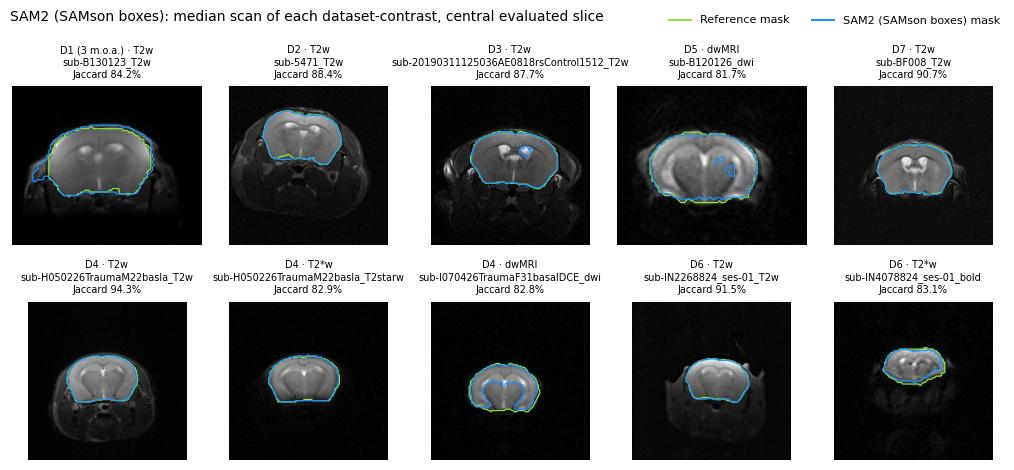

In [ ]:
plot_median_scans("sam2", "sam2_samson_boxes")

# 2. MedSAM (SAMson boxes)
MedSAM ViT-B (`medsam_vit_b.pth`) with segment-anything 1.0 in the `samson` environment (Python 3.11.7, torch 2.4.1+cu121), on the GPU: `segment_volume(volume, [(full_auto_boxes, False)], model=medsam_predictor)` with SAMson's Full-Auto boxes and post-processing. Full run: 16 min (409 scans, one at a time on the RTX A6000).

In [7]:
REGENERATE = False   # True: re-run the tool on every scan into regenerate_root (about 16 min on the GPU); False: compute only missing masks
generate_masks("medsam_samson_boxes", REGENERATE)

medsam_samson_boxes: 409 scans | 409 masks already in outputs/masks/medsam_samson_boxes | 0 computed


In [8]:
evaluate_tool_masks("medsam", "medsam_samson_boxes", show_boxes=True, dpi=50)


D1_T2w     | 53 scans | mean Jaccard 0.5028 | median scan sub-B120123_T2w (Jaccard 0.5045)

D2_T2w     | 10 scans | mean Jaccard 0.5034 | median scan sub-6088_T2w (Jaccard 0.5081)

D3_T2w     | 12 scans | mean Jaccard 0.4996 | median scan sub-20190227105648AE0818rsControl1111_T2w (Jaccard 0.4903)

D4_T2w     | 15 scans | mean Jaccard 0.5460 | median scan sub-I050226M23_T2w (Jaccard 0.5715)

D4_T2starw | 15 scans | mean Jaccard 0.5611 | median scan sub-H050226M22_T2starw (Jaccard 0.5608)

D4_DWI     | 15 scans | mean Jaccard 0.5771 | median scan sub-O080426M34_dwi (Jaccard 0.5908)

D5_DWI     | 82 scans | mean Jaccard 0.5428 | median scan sub-B290125_dwi (Jaccard 0.5565)

D6_T2w     | 96 scans | mean Jaccard 0.5107 | median scan sub-IN4078624_ses-04_T2w (Jaccard 0.5096)

D6_BOLD    | 95 scans | mean Jaccard 0.3899 | median scan sub-IN2268724_ses-01_bold (Jaccard 0.3866)

D7_T2w     | 16 scans | mean Jaccard 0.5751 | median scan sub-BF003_T2w (Jaccard 0.5876)


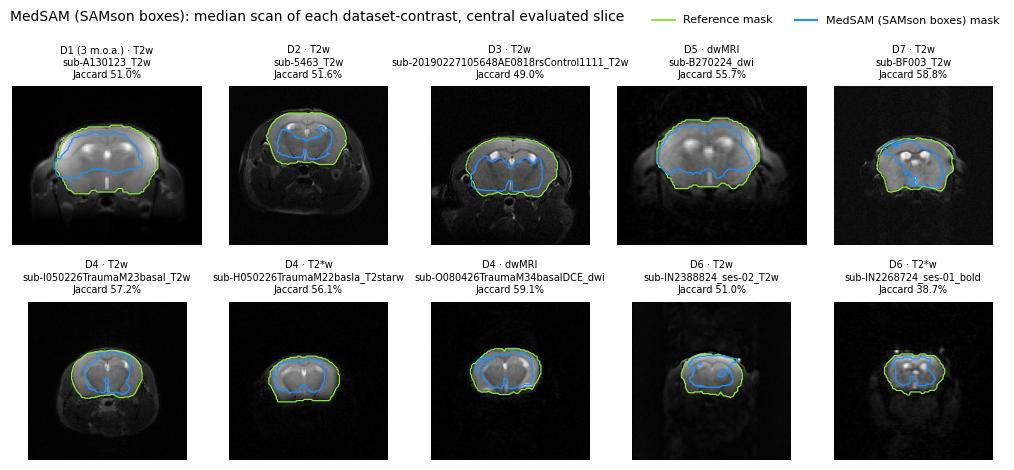

In [ ]:
plot_median_scans("medsam", "medsam_samson_boxes")

# 3. BET
FSL 6.0.7.4 (fsl-bet2 2111.4), environment `fsl_6.0.7.4`, one thread per scan, input with the ×10 header: `bet <input> <prefix> -m -r 40 -f 0.2 -g 0.07`.
Dataset-specific settings (`config.DATASET_SPECIFIC_SETTINGS`):
- D1_T2w: `bet <input> <prefix> -m -r 40 -c 55 42 7 -f 0.44 -g 0.027`
- D2_T2w: `bet <input> <prefix> -m -r 40 -c 126 173 10 -f 0.2 -g 0.07`

Full run: 38 s (409 scans, up to 80 at a time).

In [9]:
REGENERATE = False   # True: re-run the tool on every scan into regenerate_root (less than a minute on 80 threads); False: compute only missing masks
generate_masks("bet", REGENERATE)

bet: 409 scans | 409 masks already in outputs/masks/bet | 0 computed


In [10]:
evaluate_tool_masks("bet", "bet")


D1_T2w     | 53 scans | mean Jaccard 0.7488 | median scan sub-B120123_T2w (Jaccard 0.7791)

D2_T2w     | 10 scans | mean Jaccard 0.7312 | median scan sub-6092_T2w (Jaccard 0.7233)

D3_T2w     | 12 scans | mean Jaccard 0.8208 | median scan sub-20190227125730AE0818rsControl1311_T2w (Jaccard 0.8227)

D4_T2w     | 15 scans | mean Jaccard 0.8862 | median scan sub-I040226F20_T2w (Jaccard 0.8870)

D4_T2starw | 15 scans | mean Jaccard 0.8506 | median scan sub-F030226M26_T2starw (Jaccard 0.8612)

D4_DWI     | 15 scans | mean Jaccard 0.8470 | median scan sub-H050226M22_dwi (Jaccard 0.8525)

D5_DWI     | 82 scans | mean Jaccard 0.7035 | median scan sub-B080425_dwi (Jaccard 0.7033)

D6_T2w     | 96 scans | mean Jaccard 0.4334 | median scan sub-IN2388224_ses-02_T2w (Jaccard 0.4692)

D6_BOLD    | 95 scans | mean Jaccard 0.7505 | median scan sub-IN4078924_ses-02_bold (Jaccard 0.7513)

D7_T2w     | 16 scans | mean Jaccard 0.8823 | median scan sub-WF008_T2w (Jaccard 0.8824)


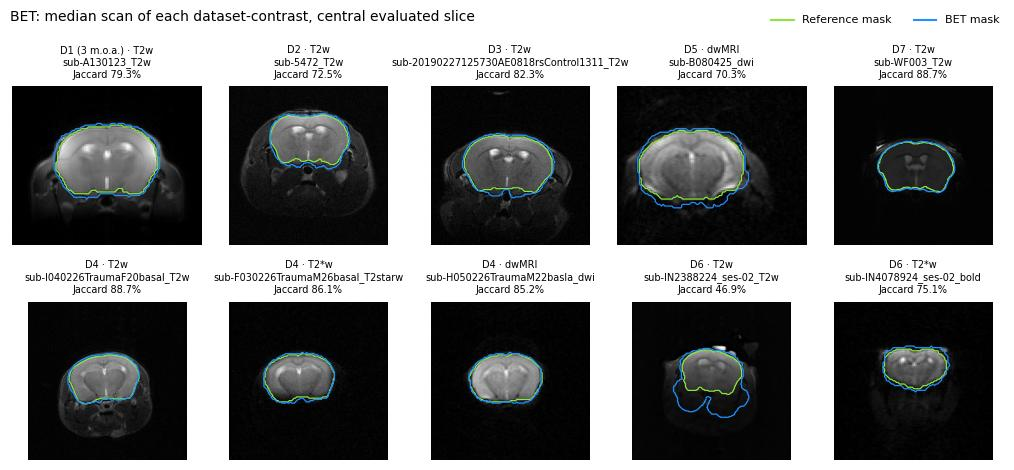

In [ ]:
plot_median_scans("bet", "bet")

# 4. BET4Animal
FSL 6.0.7.17 (bet4animal script 1.1, fsl-bet2 2111.8), environment `fsl_6.0.7.17`, one thread per scan, input with the ×10 header: `bet4animal <input> <prefix>.nii.gz "-m -x 1.6,1.2,2 -r 40 -f 0.4 -g 0"` (the scales 1.6, 1.2, 2 on the ×10 header equal `-z 6`, mouse, on the real voxel size).
Dataset-specific settings (`config.DATASET_SPECIFIC_SETTINGS`; input with the real voxel size):
- D2_T2w: `bet4animal <input> <prefix>.nii.gz "-m -z 6 -r 6 -c 126 173 10 -f 0.44 -g 0.07"`
- D3_T2w: `bet4animal <input> <prefix>.nii.gz "-m -z 6 -r 4 -c 87 87 23 -f 0.4 -g 0"`

Full run: 41 s (409 scans, up to 80 at a time).

In [11]:
REGENERATE = False   # True: re-run the tool on every scan into regenerate_root (less than a minute on 80 threads); False: compute only missing masks
generate_masks("bet4animal", REGENERATE)

bet4animal: 409 scans | 409 masks already in outputs/masks/bet4animal | 0 computed


In [12]:
evaluate_tool_masks("bet4animal", "bet4animal")


D1_T2w     | 53 scans | mean Jaccard 0.7186 | median scan sub-C120123_T2w (Jaccard 0.7205)

D2_T2w     | 10 scans | mean Jaccard 0.7456 | median scan sub-6093_T2w (Jaccard 0.7346)

D3_T2w     | 12 scans | mean Jaccard 0.6598 | median scan sub-20190311125036AE0818rsControl1512_T2w (Jaccard 0.6604)

D4_T2w     | 15 scans | mean Jaccard 0.9029 | median scan sub-I070426F31_T2w (Jaccard 0.9028)

D4_T2starw | 15 scans | mean Jaccard 0.9027 | median scan sub-O080426M34_T2starw (Jaccard 0.9078)

D4_DWI     | 15 scans | mean Jaccard 0.8868 | median scan sub-H040226F19_dwi (Jaccard 0.8881)

D5_DWI     | 82 scans | mean Jaccard 0.7331 | median scan sub-B090724_dwi (Jaccard 0.7328)

D6_T2w     | 96 scans | mean Jaccard 0.7797 | median scan sub-IN2168324_ses-03_T2w (Jaccard 0.7796)

D6_BOLD    | 95 scans | mean Jaccard 0.7581 | median scan sub-IN4079024_ses-04_bold (Jaccard 0.7562)

D7_T2w     | 16 scans | mean Jaccard 0.9166 | median scan sub-BF009_T2w (Jaccard 0.9181)


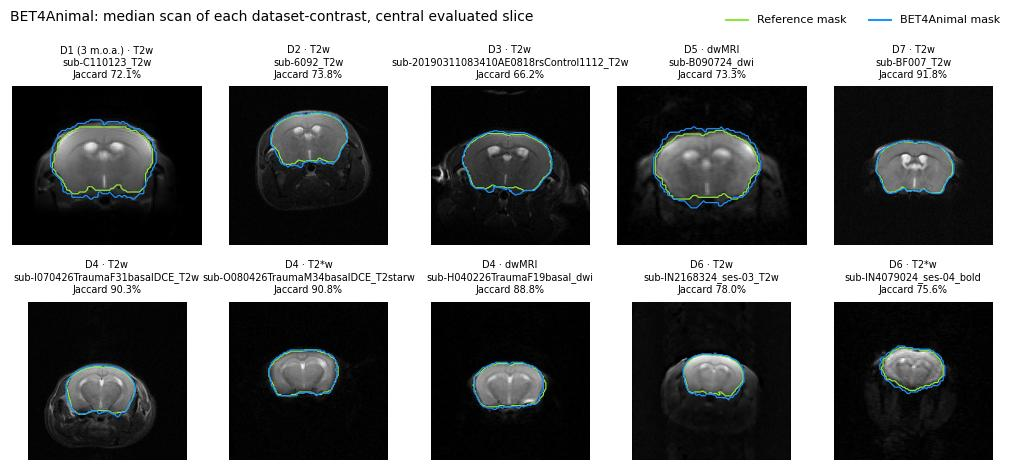

In [ ]:
plot_median_scans("bet4animal", "bet4animal")

# 5. deepbet
deepbet 1.0.2 (PyPI), environment `deepbet_1_env` (Python 3.12.7, torch 2.5.0), on the GPU (CPU masks differ by a few voxels). Runner `runners/deepbet_run.py`: `BrainExtraction(no_gpu=False).run(input, brain, mask, tiv, threshold=0.95, n_dilate=0)`, as `deepbet.run_bet`. Input with the ×10 header and anatomical orientation labels (axis 1 → S, axis 2 → A: direction-cosine columns 1 and 2 exchanged for D1, D2 and D5; voxel data unchanged). Full run: 85 s (409 scans, one at a time).

In [13]:
REGENERATE = False   # True: re-run the tool on every scan into regenerate_root (about 1.5 min on the GPU); False: compute only missing masks
generate_masks("deepbet", REGENERATE)

deepbet: 409 scans | 409 masks already in outputs/masks/deepbet | 0 computed


In [14]:
evaluate_tool_masks("deepbet", "deepbet")


D1_T2w     | 53 scans | mean Jaccard 0.8033 | median scan sub-B170123_T2w (Jaccard 0.8109)

D2_T2w     | 10 scans | mean Jaccard 0.6406 | median scan sub-6087_T2w (Jaccard 0.6323)

D3_T2w     | 12 scans | mean Jaccard 0.8241 | median scan sub-20190311083410AE0818rsControl1112_T2w (Jaccard 0.8363)

D4_T2w     | 15 scans | mean Jaccard 0.5835 | median scan sub-H040226F19_T2w (Jaccard 0.5806)

D4_T2starw | 15 scans | mean Jaccard 0.7302 | median scan sub-I070426F31_T2starw (Jaccard 0.7247)

D4_DWI     | 15 scans | mean Jaccard 0.7371 | median scan sub-N090426F30_dwi (Jaccard 0.7613)

D5_DWI     | 82 scans | mean Jaccard 0.7643 | median scan sub-B180625_dwi (Jaccard 0.7682)

D6_T2w     | 96 scans | mean Jaccard 0.5066 | median scan sub-IN2268724_ses-03_T2w (Jaccard 0.4821)

D6_BOLD    | 95 scans | mean Jaccard 0.5043 | median scan sub-IN2388624_ses-03_bold (Jaccard 0.4934)

D7_T2w     | 16 scans | mean Jaccard 0.7940 | median scan sub-WF003_T2w (Jaccard 0.8571)


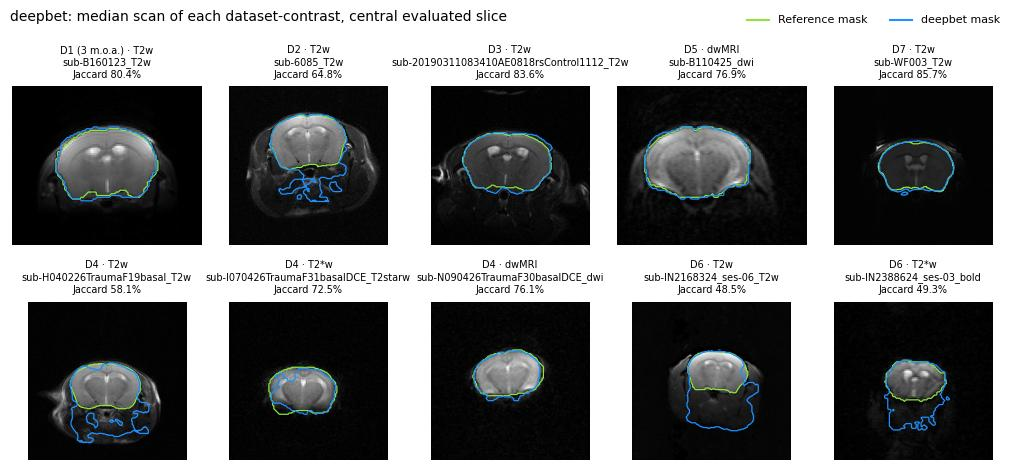

In [ ]:
plot_median_scans("deepbet", "deepbet")

# 6. BEN
BEN (commit f23ed39), environment `ben` (Python 3.7.16, TensorFlow 1.15.4 on the CPU, Keras 2.2.4), weight Mouse-T2WI-7T, one thread per scan: `python BEN_infer.py -i <input folder> -o <output folder> -weight weight/Mouse_T2WI_7T_2022_07191047/` (no `-check`). Input with the ×10 header and axis 1 reversed (dorsal-up coronal slices); the mask is reversed back. Full run: 108 s (409 scans, up to 80 at a time).

In [15]:
REGENERATE = False   # True: re-run the tool on every scan into regenerate_root (about 2 min on 80 threads); False: compute only missing masks
generate_masks("ben", REGENERATE)

ben: 409 scans | 409 masks already in outputs/masks/ben | 0 computed


In [16]:
evaluate_tool_masks("ben", "ben")


D1_T2w     | 53 scans | mean Jaccard 0.8407 | median scan sub-C100323_T2w (Jaccard 0.8489)

D2_T2w     | 10 scans | mean Jaccard 0.8144 | median scan sub-6088_T2w (Jaccard 0.8105)

D3_T2w     | 12 scans | mean Jaccard 0.7680 | median scan sub-20190311143920AE0818rsControl2112_T2w (Jaccard 0.7671)

D4_T2w     | 15 scans | mean Jaccard 0.9359 | median scan sub-O080426M34_T2w (Jaccard 0.9344)

D4_T2starw | 15 scans | mean Jaccard 0.8109 | median scan sub-J070426F32_T2starw (Jaccard 0.8170)

D4_DWI     | 15 scans | mean Jaccard 0.6552 | median scan sub-G040226F18_dwi (Jaccard 0.6405)

D5_DWI     | 82 scans | mean Jaccard 0.8042 | median scan sub-B181125_dwi (Jaccard 0.8168)

D6_T2w     | 96 scans | mean Jaccard 0.8478 | median scan sub-IN4079024_ses-03_T2w (Jaccard 0.8565)

D6_BOLD    | 95 scans | mean Jaccard 0.4767 | median scan sub-IN4078724_ses-06_bold (Jaccard 0.4712)

D7_T2w     | 16 scans | mean Jaccard 0.9266 | median scan sub-WF007_T2w (Jaccard 0.9300)


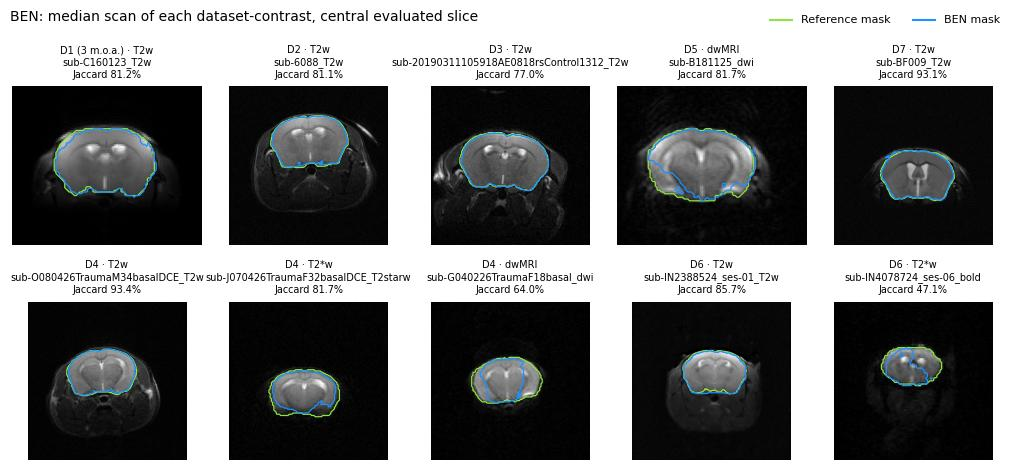

In [ ]:
plot_median_scans("ben", "ben")

# 7. Rodent U-net (RBM)
RodentMRISkullStripping (commit dfa1a12), model `rat_brain-2d_unet.hdf5`, environment `ben` (Keras 2.2.4, TensorFlow 1.15.4 on the CPU), one thread per scan. Runner `runners/rbm_unet_run_padded.py jobs.json` with `voxsize = 1.0` (×10 header units = 0.1 mm). Input with the ×10 header and axis 1 reversed (dorsal-up coronal slices); the mask is reversed back.
Dataset-specific setting (`config.DATASET_SPECIFIC_SETTINGS`):
- D3_T2w: canonical image, axis 1 not reversed

Full run: 10 min (409 scans, up to 80 at a time).

In [17]:
REGENERATE = False   # True: re-run the tool on every scan into regenerate_root (about 10 min on 80 threads); False: compute only missing masks
generate_masks("rbm", REGENERATE)

rbm: 409 scans | 409 masks already in outputs/masks/rbm | 0 computed


In [18]:
evaluate_tool_masks("rbm", "rbm")


D1_T2w     | 53 scans | mean Jaccard 0.6701 | median scan sub-A100323_T2w (Jaccard 0.6702)

D2_T2w     | 10 scans | mean Jaccard 0.7639 | median scan sub-6085_T2w (Jaccard 0.7660)

D3_T2w     | 12 scans | mean Jaccard 0.7790 | median scan sub-20190311083410AE0818rsControl1112_T2w (Jaccard 0.7945)

D4_T2w     | 15 scans | mean Jaccard 0.8735 | median scan sub-I050226M23_T2w (Jaccard 0.8736)

D4_T2starw | 15 scans | mean Jaccard 0.8774 | median scan sub-M090426F29_T2starw (Jaccard 0.8847)

D4_DWI     | 15 scans | mean Jaccard 0.8920 | median scan sub-O080426M34_dwi (Jaccard 0.8927)

D5_DWI     | 82 scans | mean Jaccard 0.6819 | median scan sub-B160424_dwi (Jaccard 0.6828)

D6_T2w     | 96 scans | mean Jaccard 0.7632 | median scan sub-IN2268824_ses-06_T2w (Jaccard 0.7669)

D6_BOLD    | 95 scans | mean Jaccard 0.5994 | median scan sub-IN2388524_ses-03_bold (Jaccard 0.5929)

D7_T2w     | 16 scans | mean Jaccard 0.8602 | median scan sub-WF007_T2w (Jaccard 0.8625)


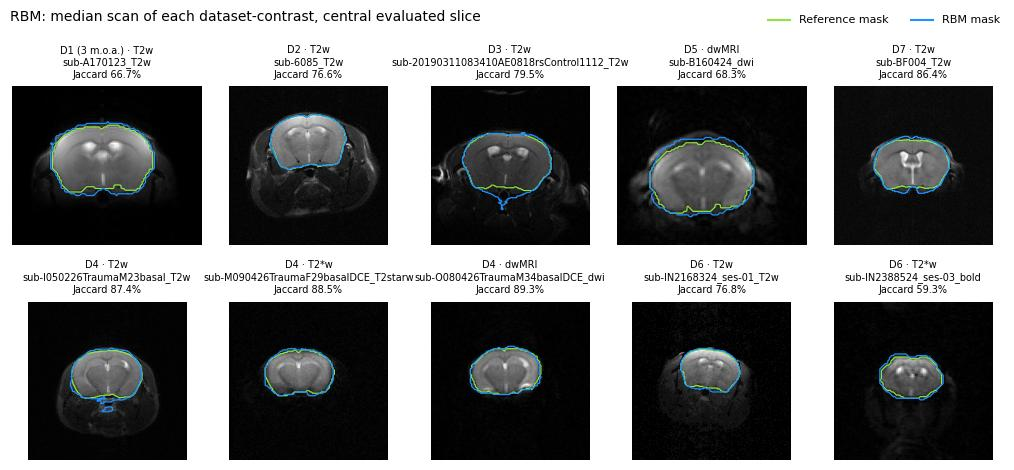

In [ ]:
plot_median_scans("rbm", "rbm")

# 8. ANTs
ANTs 2.5.0 (`SAMSON_ANTS_BIN`), one thread per scan (`ITK_GLOBAL_DEFAULT_NUMBER_OF_THREADS=1`), input with the ×10 header: `antsBrainExtraction.sh -d 3 -a <input> -e datasets/template/anat_template_FP.nii.gz -m datasets/template/anat_template_FP_mask.nii.gz -u 0 -o <prefix>`. D4 (6 slices) is zero-padded to 8 slices and the mask cropped back. Full run: ≈ 16 h (58,757 s; 409 scans on 80 threads, 1.8–4.2 h per scan).

In [19]:
REGENERATE = False   # True: re-run the tool on every scan into regenerate_root (≈ 16 h on 80 threads); False: compute only missing masks
generate_masks("ants", REGENERATE)

ants: 409 scans | 409 masks already in outputs/masks/ants | 0 computed


In [20]:
evaluate_tool_masks("ants", "ants")


D1_T2w     | 53 scans | mean Jaccard 0.5489 | median scan sub-C070222_T2w (Jaccard 0.5614)

D2_T2w     | 10 scans | mean Jaccard 0.7292 | median scan sub-6289_T2w (Jaccard 0.7100)

D3_T2w     | 12 scans | mean Jaccard 0.7011 | median scan sub-20190311115813AE0818rsControl1412_T2w (Jaccard 0.6890)

D4_T2w     | 15 scans | mean Jaccard 0.7327 | median scan sub-H040226F19_T2w (Jaccard 0.7482)

D4_T2starw | 15 scans | mean Jaccard 0.7831 | median scan sub-P080426M35_T2starw (Jaccard 0.7874)

D4_DWI     | 15 scans | mean Jaccard 0.8027 | median scan sub-H040226F19_dwi (Jaccard 0.8028)

D5_DWI     | 82 scans | mean Jaccard 0.6284 | median scan sub-B090924_dwi (Jaccard 0.6241)

D6_T2w     | 96 scans | mean Jaccard 0.6640 | median scan sub-IN4078724_ses-01_T2w (Jaccard 0.6856)

D6_BOLD    | 95 scans | mean Jaccard 0.7212 | median scan sub-IN2268724_ses-06_bold (Jaccard 0.7370)

D7_T2w     | 16 scans | mean Jaccard 0.7661 | median scan sub-WF005_T2w (Jaccard 0.7677)


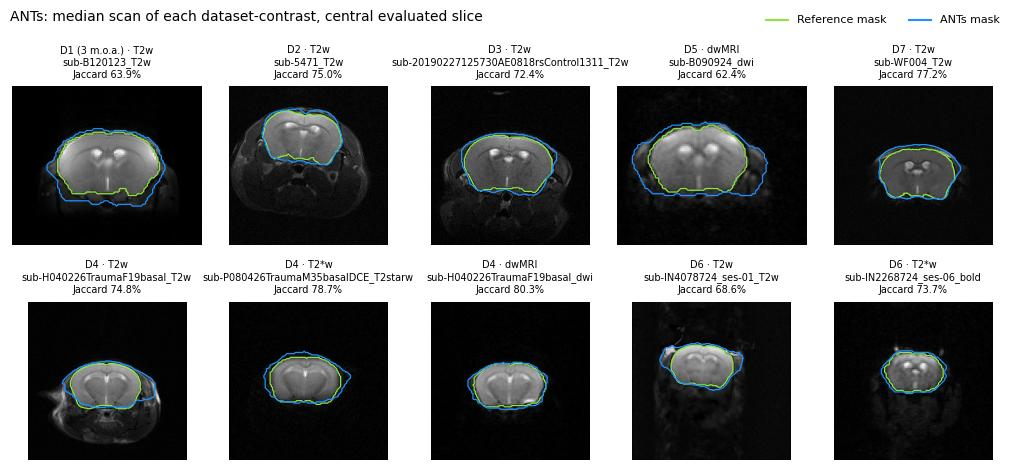

In [ ]:
plot_median_scans("ants", "ants")

# 9. SHERM
SHERM is MATLAB code and was run on two other computers: see [`runners/sherm/README.md`](runners/sherm/README.md) (`run_sherm_samson.m`; VLFeat 0.9.21; real voxel size, `'mouse'`, anisotropic mode). D1 and D3–D6 come from run 1 (MATLAB R2021a) and D2 and D7 from run 2 (MATLAB R2023b). The masks are read from `outputs/masks/sherm/` and evaluated as those of the other tools; the logs of the 409 masks, the environment of each run and the run times are in `outputs/sherm/`.

In [21]:
evaluate_tool_masks("sherm", "sherm")


D1_T2w     | 53 scans | mean Jaccard 0.8607 | median scan sub-A140323_T2w (Jaccard 0.8703)

D2_T2w     | 10 scans | mean Jaccard 0.8285 | median scan sub-6092_T2w (Jaccard 0.8417)

D3_T2w     | 12 scans | mean Jaccard 0.8288 | median scan sub-20190227125730AE0818rsControl1311_T2w (Jaccard 0.8288)

D4_T2w     | 15 scans | mean Jaccard 0.8290 | median scan sub-Q080426M36_T2w (Jaccard 0.9014)

D4_T2starw | 15 scans | mean Jaccard 0.7349 | median scan sub-Q080426M36_T2starw (Jaccard 0.7219)

D4_DWI     | 15 scans | mean Jaccard 0.7550 | median scan sub-F030226M26_dwi (Jaccard 0.7691)

D5_DWI     | 82 scans | mean Jaccard 0.8624 | median scan sub-B130924_dwi (Jaccard 0.8735)

D6_T2w     | 96 scans | mean Jaccard 0.8909 | median scan sub-IN4079124_ses-01_T2w (Jaccard 0.8917)

D6_BOLD    | 95 scans | mean Jaccard 0.8075 | median scan sub-IN2168324_ses-02_bold (Jaccard 0.8092)

D7_T2w     | 16 scans | mean Jaccard 0.9432 | median scan sub-WF008_T2w (Jaccard 0.9475)


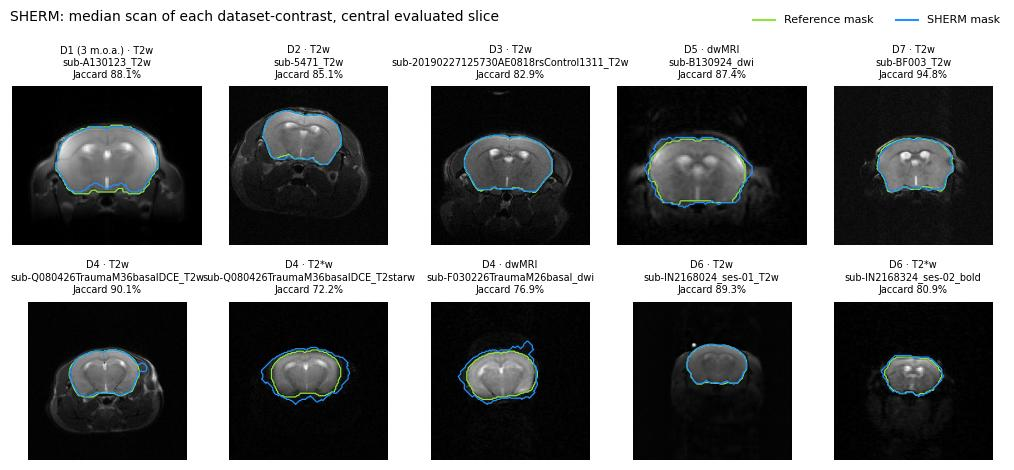

In [ ]:
plot_median_scans("sherm", "sherm")

In [22]:
save_results("exp_tools")

Saved 67482 slice rows and 3681 subject rows to results/exp_tools_*.csv


## SHERM run times
Wall time per scan of the 409 SHERM masks used, from the logs of its two runs (`outputs/sherm/logs/`; run and computer from `outputs/sherm/environment_run1.json` and `environment_run2.json`), written to `results/sherm_runtimes.csv` for `SAMson_figures_and_statistics` (the times of the other methods are in `results/runtimes.csv`, written by `run_all.py`).

In [23]:
sherm_runtimes = sherm.scan_runtimes(pjoin(P, "outputs", "sherm"), pjoin(P, "datasets", "participants.tsv"))
assert len(sherm_runtimes) == len(scans) and (sherm_runtimes.status == "ok").all()
assert all(os.path.exists(pjoin(masks_path, "sherm", s.dataset, s.rel_dir, f"{s.stem}_mask.nii.gz")) for s in scans)
sherm_runtimes.to_csv(pjoin(results_path, "sherm_runtimes.csv"), index=False)
print(f"Saved {len(sherm_runtimes)} scan rows to {os.path.relpath(results_path, P)}/sherm_runtimes.csv")
sherm_runtimes.groupby(["sherm_run", "computer", "matlab", "dataset"]).agg(scans=("stem", "size"), median_s=("seconds", "median"),
                                                                           workers_min=("workers", "min"), workers_max=("workers", "max")).round(1)

Saved 409 scan rows to results/sherm_runtimes.csv


scans  \
sherm_run computer                                       matlab dataset          
1         AMD Ryzen Threadripper 1950X 16-Core Processor 2021a  D1          53   
                                                                D3          12   
                                                                D4          45   
                                                                D5          82   
                                                                D6         191   
2         13th Gen Intel(R) Core(TM) i5-13600K           2023b  D2          10   
                                                                D7          16   

                                                                         median_s  \
sherm_run computer                                       matlab dataset             
1         AMD Ryzen Threadripper 1950X 16-Core Processor 2021a  D1           49.5   
                                                                D3          495.5   
                                                                D4           22.3   
                                                                D5           57.7   
                                                                D6          174.9   
2         13th Gen Intel(R) Core(TM) i5-13600K           2023b  D2         1239.5   
                                                                D7        14472.3   

                                                                         workers_min  \
sherm_run computer                                       matlab dataset                
1         AMD Ryzen Threadripper 1950X 16-Core Processor 2021a  D1                 8   
                                                                D3                 6   
                                                                D4                 5   
                                                                D5                 8   
                                                                D6                 8   
2         13th Gen Intel(R) Core(TM) i5-13600K           2023b  D2                 1   
                                                                D7                 1   

                                                                         workers_max  
sherm_run computer                                       matlab dataset               
1         AMD Ryzen Threadripper 1950X 16-Core Processor 2021a  D1                 8  
                                                                D3                 6  
                                                                D4                 8  
                                                                D5                 8  
                                                                D6                 8  
2         13th Gen Intel(R) Core(TM) i5-13600K           2023b  D2                 1  
                                                                D7                 1

## Check
The scan metrics of this notebook equal those of the full-run evaluation (`results/subjects.csv`, `lib/evaluation.py`) for the same tools.

In [24]:
subjects_table = pd.read_csv(pjoin(results_path, "exp_tools_subjects.csv"), dtype={"group": str, "session": str})
columns = ["n_slices", "accuracy", "jaccard", "dice", "failed_slices", "jaccard_3d", "dice_3d", "hd95_mm", "volume_bias_pct"]
keys = ["method", "dataset", "contrast", "subject", "session"]
full_run = pd.read_csv(pjoin(results_path, "subjects.csv"), dtype={"subject": str, "session": str, "group": str})
full_run = full_run[full_run.tool.isin(TOOL_KEYS.values()) & (full_run.status != "missing")]   # missing masks (none)
full_run["method"] = full_run.tool.map({key: method for method, key in TOOL_KEYS.items()})
merged = subjects_table.fillna({"session": ""}).merge(full_run.fillna({"session": ""}), on=keys, how="outer",
                                                      suffixes=("", "_full_run"), indicator=True)
differences = {c: np.nanmax(np.abs(merged[c] - merged[f"{c}_full_run"])) for c in columns}
same_nan = (merged.hd95_mm.isna() == merged.hd95_mm_full_run.isna()).all()
print(f"{(merged._merge == 'both').sum()} scan rows matched, {(merged._merge != 'both').sum()} unmatched; HD95 undefined in the same rows: {same_nan}")
print("max |difference|:", ", ".join(f"{c} {d:.1e}" for c, d in differences.items()))
assert (merged._merge == "both").all() and same_nan and max(differences.values()) < 1e-9

3681 scan rows matched, 0 unmatched; HD95 undefined in the same rows: True
max |difference|: n_slices 0.0e+00, accuracy 2.3e-13, jaccard 4.4e-16, dice 4.4e-16, failed_slices 0.0e+00, jaccard_3d 0.0e+00, dice_3d 0.0e+00, hd95_mm 8.9e-16, volume_bias_pct 0.0e+00
